# Machine Learning Assignment 2
## Dry Bean Variety Classification Using Multiple Machine Learning Models

### 1. Project Overview

This project implements and compares multiple supervised machine learning classification models on the UCI Dry Bean Dataset.

The objective is to classify dry bean varieties using morphological and shape-related characteristics extracted from bean images. Five classification algorithms are implemented and evaluated using multiple performance metrics, followed by deployment of the trained models through an interactive Streamlit web application.

### Models Implemented

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbor Classifier
4. Gaussian Naive Bayes
5. Random Forest Classifier

### Evaluation Metrics

The models are evaluated using:

- Accuracy
- AUC Score
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

### Project Workflow

The overall workflow followed in this project is:

**Dataset Loading → Data Inspection → Data Quality Assessment → Exploratory Data Analysis → Data Preprocessing → Train-Test Split → Model Training → Model Evaluation → Model Comparison → Model Selection → Model Serialization → Streamlit Deployment**

## 2. Import Required Libraries

The following Python libraries are used for data loading and manipulation, exploratory data analysis, visualization, data preprocessing, machine learning model development, and evaluation.

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Machine learning classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Display options
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

## 3. Load the Dataset

The Dry Bean Dataset is provided in Excel format. The dataset contains morphological and shape-related measurements of dry beans, with the bean variety represented by the `Class` column.

The dataset will be loaded into a Pandas DataFrame for subsequent inspection and analysis.

In [2]:
# Load the Dry Bean dataset
file_path = r"C:\Users\arman\Desktop\ML_A2_Dry_Bean\Data\Dry_Bean_Dataset.xlsx"

df = pd.read_excel(file_path)

# Display the first five records
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.2910,208.1781,173.8887,1.1972,0.5498,28715,190.1411,0.7639,0.9889,0.9580,0.9134,0.0073,0.0031,0.8342,0.9987,SEKER
1,28734,638.0180,200.5248,182.7344,1.0974,0.4118,29172,191.2728,0.7840,0.9850,0.8870,0.9539,0.0070,0.0036,0.9099,0.9984,SEKER
2,29380,624.1100,212.8261,175.9311,1.2097,0.5627,29690,193.4109,0.7781,0.9896,0.9478,0.9088,0.0072,0.0030,0.8259,0.9991,SEKER
3,30008,645.8840,210.5580,182.5165,1.1536,0.4986,30724,195.4671,0.7827,0.9767,0.9039,0.9283,0.0070,0.0032,0.8618,0.9942,SEKER
4,30140,620.1340,201.8479,190.2793,1.0608,0.3337,30417,195.8965,0.7731,0.9909,0.9849,0.9705,0.0067,0.0037,0.9419,0.9992,SEKER


## 4. Initial Dataset Overview

Before performing preprocessing or model development, the dataset is examined to determine its dimensions, feature names, data types, and overall structure.

In [3]:
# Display dataset dimensions
print(f"Number of observations: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types
print("\nData types:")
display(df.dtypes)

Number of observations: 13611
Number of columns: 17

Column names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Data types:


Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object
dtype: object

## 5. Data Quality Assessment

Before proceeding with exploratory data analysis and model development, the dataset is checked for missing values, duplicate observations, and the distribution of the target classes.

These checks help identify potential data-quality issues and ensure that appropriate preprocessing decisions are made before model training.

### 5.1 Missing Value Analysis

The dataset is examined for missing values in each feature and in the target variable.

In [4]:
# Check for missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

print(f"\nTotal missing values in the dataset: {missing_values.sum()}")

Missing values in each column:


Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64


Total missing values in the dataset: 0


### 5.2 Duplicate Observation Analysis

The dataset is checked for completely duplicated rows. Duplicate observations can cause the same record to appear more than once and may lead to an unrepresentative evaluation if identical records are distributed across training and testing datasets.

In [5]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 68


### 5.3 Target Variable Analysis

The `Class` column represents the target variable. The unique class labels and their frequencies are examined to understand the distribution of the seven dry bean varieties.

In [6]:
# Display unique target classes
print("Unique classes:")
print(df["Class"].unique())

print(f"\nNumber of classes: {df['Class'].nunique()}")

Unique classes:
['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']

Number of classes: 7


In [7]:
# Calculate class frequencies
class_counts = df["Class"].value_counts().reset_index()
class_counts.columns = ["Class", "Counts"]

print("Class distribution:")
display(class_counts.style.hide(axis="index"))

Class distribution:


Class,Counts
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


### 5.4 Class Distribution by Percentage

In addition to the number of observations in each class, the percentage distribution is calculated to assess whether the target variable is balanced across the seven bean varieties.

In [8]:
# Calculate class distribution percentages
class_distribution = df["Class"].value_counts().reset_index()
class_distribution.columns = ["Class", "Count"]

# Calculate percentages
class_distribution["Percentage"] = (
    class_distribution["Count"] / class_distribution["Count"].sum() * 100
).round(4)

# Display without the index
print("Class distribution by Percentage:")
display(class_distribution.style.hide(axis="index"))

Class distribution by Percentage:


Class,Count,Percentage
DERMASON,3546,26.052500
SIRA,2636,19.366700
SEKER,2027,14.892400
HOROZ,1928,14.165000
CALI,1630,11.975600
BARBUNYA,1322,9.712700
BOMBAY,522,3.835100


### 5.5 Visualization of Class Distribution

A bar chart is used to visualize the number of observations belonging to each dry bean variety.

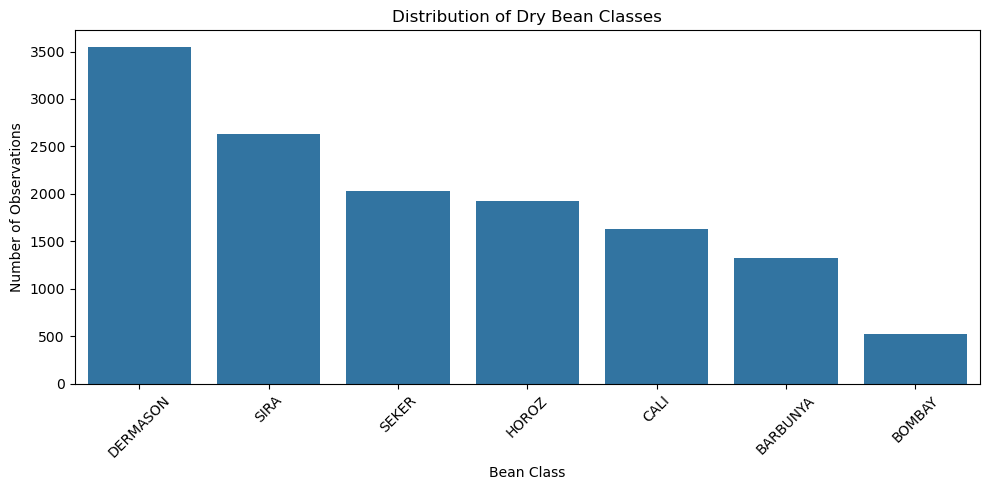

In [9]:
# Visualize class distribution
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Class",
    order=df["Class"].value_counts().index
)

plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Class")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 6. Data Cleaning and Preparation

Based on the data-quality assessment, the dataset contains no missing values. However, 68 completely duplicated observations were identified.

The duplicate observations are removed before splitting the data into training and testing subsets. This helps avoid the possibility of identical records being present in both subsets and provides a more reliable estimate of model performance.

No missing-value imputation is required because the dataset contains no missing values.

In [10]:
# Remove duplicate observations
df_clean = df.drop_duplicates().reset_index(drop=True)

print(f"Original number of observations: {len(df)}")
print(f"Number of duplicate observations removed: {df.duplicated().sum()}")
print(f"Number of observations after removing duplicates: {len(df_clean)}")

Original number of observations: 13611
Number of duplicate observations removed: 68
Number of observations after removing duplicates: 13543


### 6.1 Verification of Duplicate Removal

The cleaned dataset is checked again to confirm that no duplicate observations remain.

In [11]:
# Verify duplicate removal
remaining_duplicates = df_clean.duplicated().sum()

print(f"Remaining duplicate observations: {remaining_duplicates}")

Remaining duplicate observations: 0


### 6.2 Cleaned Dataset Structure

The dimensions and column structure of the cleaned dataset are verified before proceeding with exploratory analysis and model development.

In [12]:
# Display cleaned dataset dimensions and columns
print(f"Number of observations: {df_clean.shape[0]}")
print(f"Number of columns: {df_clean.shape[1]}")

print("\nColumn names:")
print(df_clean.columns.tolist())

Number of observations: 13543
Number of columns: 17

Column names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


### 6.3 Target Distribution After Duplicate Removal

The target-class distribution is recalculated after duplicate removal to verify that the cleaning step has not substantially altered the representation of the seven bean varieties.

In [13]:
# Calculate class distribution after duplicate removal
clean_class_distribution = df_clean["Class"].value_counts().reset_index()
clean_class_distribution.columns = ["Class", "Count"]

# Calculate percentages
clean_class_distribution["Percentage"] = (
    clean_class_distribution["Count"] / clean_class_distribution["Count"].sum() * 100
).round(4)

# Display without the index
print("Class distribution after duplicate removal:")
display(clean_class_distribution.style.hide(axis="index"))

Class distribution after duplicate removal:


Class,Count,Percentage
DERMASON,3546,26.183300
SIRA,2636,19.463900
SEKER,2027,14.967100
HOROZ,1860,13.734000
CALI,1630,12.035700
BARBUNYA,1322,9.761500
BOMBAY,522,3.854400


## 7. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the statistical properties, distributions, relationships, and scale differences among the predictor variables.

The analysis helps identify characteristics of the dataset that may influence the performance of different classification algorithms.

### 7.1 Descriptive Statistics

Descriptive statistics are calculated for all numerical predictor variables to examine their central tendency, variability, and range.

In [14]:
# Descriptive statistics for numerical features
numeric_summary = df_clean.drop(columns="Class").describe().T

display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
Area,13543.0000,53048.4604,29392.4383,20420.0000,36282.5000,44580.0000,61382.0000,254616.0000
Perimeter,13543.0000,854.9934,214.7227,524.7360,703.2300,793.8960,977.1465,1985.3700
MajorAxisLength,13543.0000,319.8956,85.8093,183.6012,253.0868,296.4046,376.3125,738.8602
MinorAxisLength,13543.0000,202.3653,45.0516,122.5127,175.8864,192.4911,217.2454,460.1985
AspectRation,13543.0000,1.5811,0.2452,1.0249,1.4307,1.5499,1.7039,2.4303
Eccentricity,13543.0000,0.7503,0.0919,0.2190,0.7151,0.7640,0.8097,0.9114
ConvexArea,13543.0000,53767.9867,29844.2485,20684.0000,36673.0000,45122.0000,62360.0000,263261.0000
EquivDiameter,13543.0000,253.0341,59.3077,161.2438,214.9333,238.2457,279.5604,569.3744
Extent,13543.0000,0.7498,0.0489,0.5553,0.7187,0.7599,0.7868,0.8662
Solidity,13543.0000,0.9872,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947


### 7.2 Data Types of Predictor Variables

The data types of the predictor variables are examined to confirm that the features are numeric and therefore suitable for the selected machine learning algorithms.

In [15]:
# Check data types of the cleaned dataset
display(df_clean.dtypes)

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object
dtype: object

### 7.3 Distribution of Numerical Features

The distributions of the numerical predictor variables are visualized using histograms. This helps identify differences in feature ranges, skewness, and potential extreme observations.

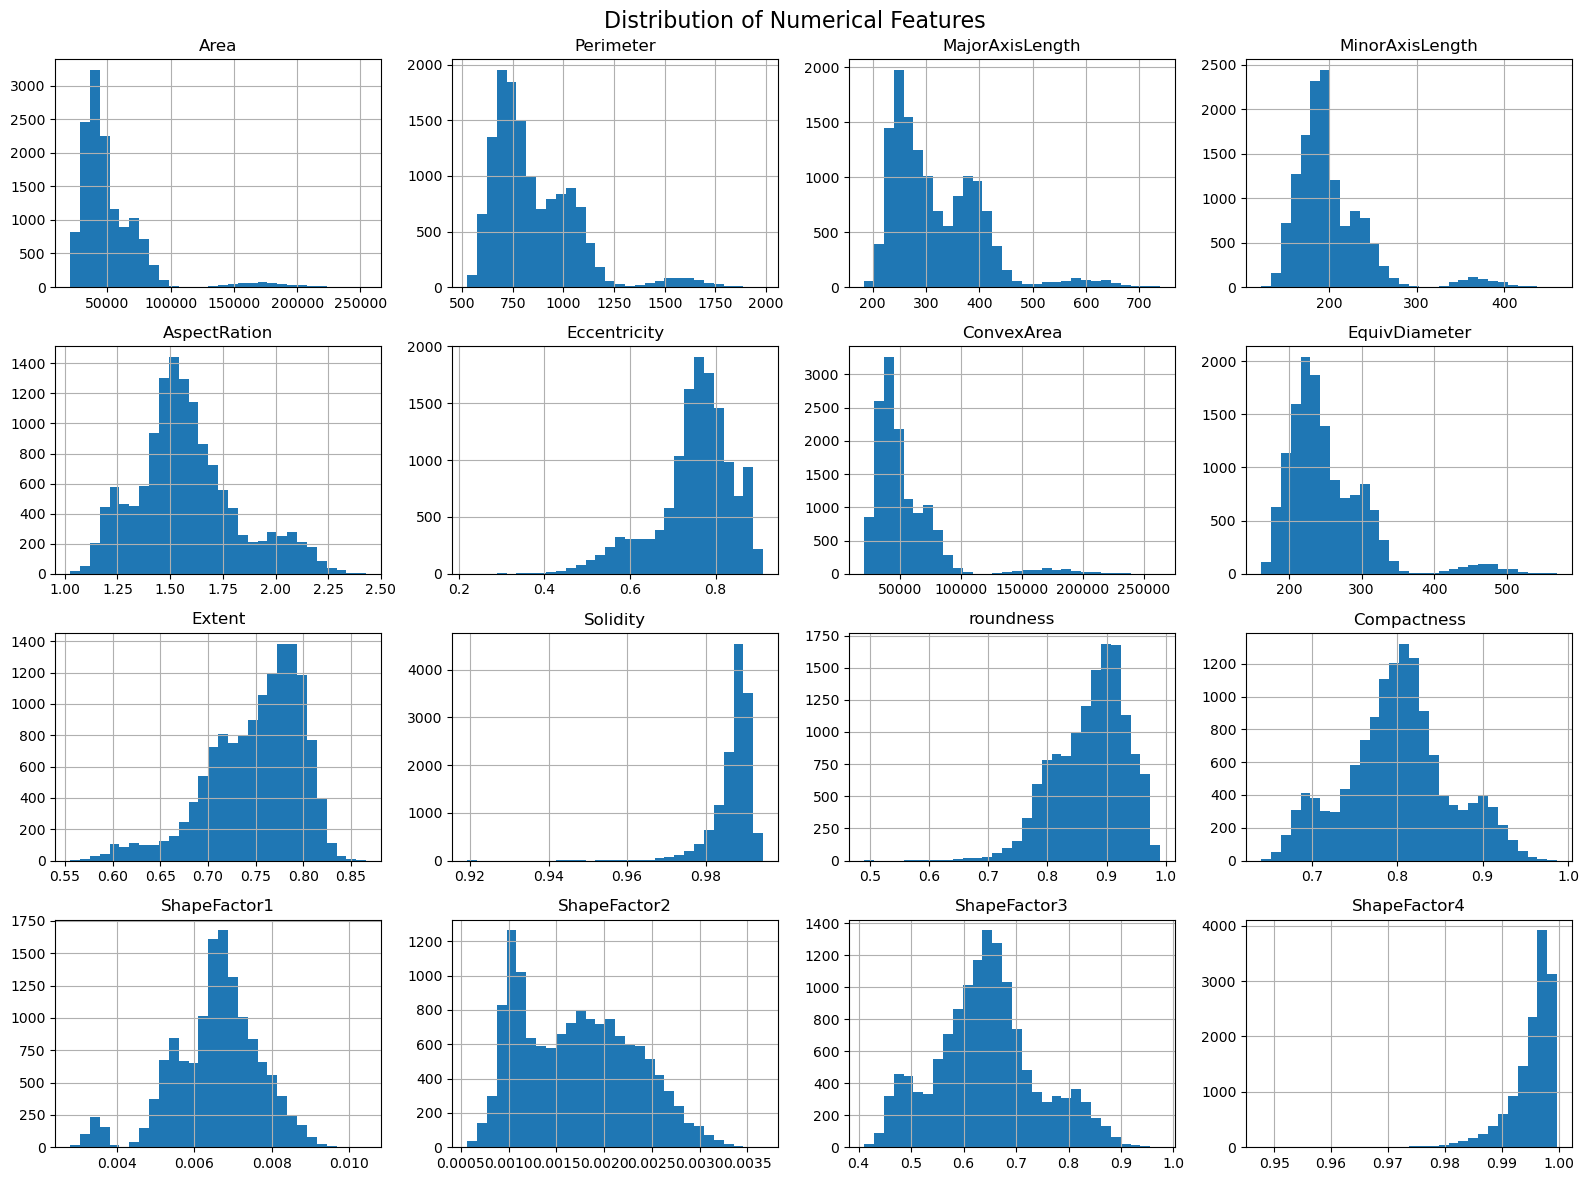

In [16]:
# Plot distributions of numerical features
df_clean.drop(columns="Class").hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

### 7.4 Feature Scale Comparison

The predictor variables have different numerical scales. This is particularly relevant for distance-based and coefficient-based algorithms such as K-Nearest Neighbors and Logistic Regression.

The ranges of the predictor variables are therefore examined before deciding on the appropriate preprocessing strategy.

In [17]:
# Display minimum and maximum values of each numerical feature
feature_ranges = pd.DataFrame({
    "Minimum": df_clean.drop(columns="Class").min(),
    "Maximum": df_clean.drop(columns="Class").max()
})

display(feature_ranges)

,Minimum,Maximum
Area,20420.0000,254616.0000
Perimeter,524.7360,1985.3700
MajorAxisLength,183.6012,738.8602
MinorAxisLength,122.5127,460.1985
AspectRation,1.0249,2.4303
Eccentricity,0.2190,0.9114
ConvexArea,20684.0000,263261.0000
EquivDiameter,161.2438,569.3744
Extent,0.5553,0.8662
Solidity,0.9192,0.9947


### 7.5 Feature Correlation Analysis

A correlation matrix is used to examine linear relationships among the numerical predictor variables.

Strong correlations may indicate that some morphological measurements contain related information because they describe different aspects of the same physical characteristics of the beans.

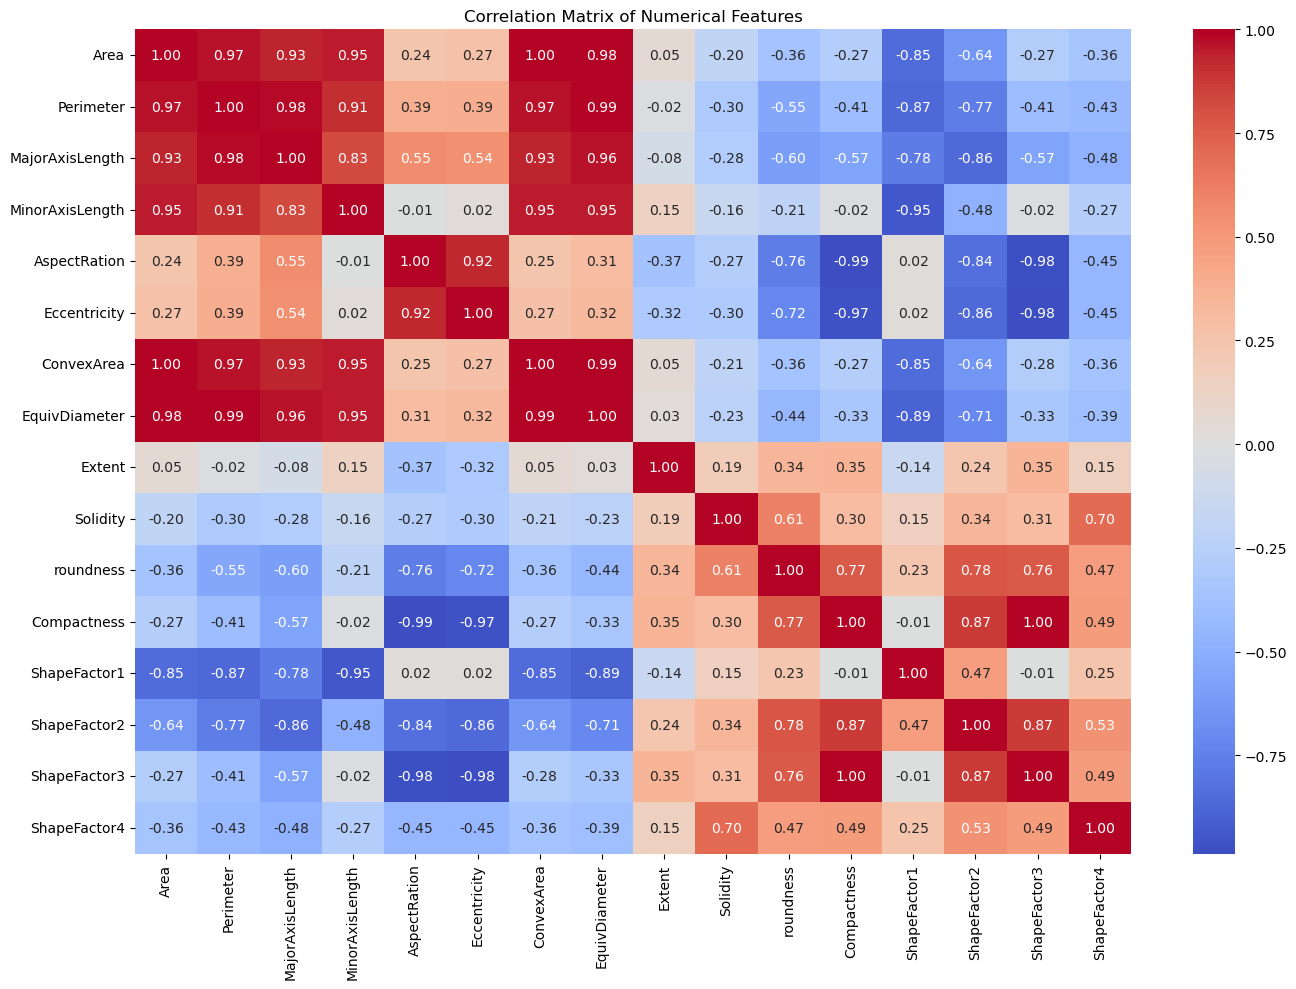

In [18]:
# Calculate feature correlation matrix
correlation_matrix = df_clean.drop(columns="Class").corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

### 7.6 Highly Correlated Feature Pairs

Feature pairs with a strong absolute correlation are identified to better understand relationships among the morphological measurements.

In [19]:
# Identify highly correlated feature pairs
corr_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=abs, ascending=False)
)

high_corr_pairs = corr_pairs[abs(corr_pairs) >= 0.80]

display(high_corr_pairs)

Area             ConvexArea         0.9999
Compactness      ShapeFactor3       0.9987
Perimeter        EquivDiameter      0.9915
AspectRation     Compactness       -0.9876
ConvexArea       EquivDiameter      0.9853
Area             EquivDiameter      0.9850
Eccentricity     ShapeFactor3      -0.9811
AspectRation     ShapeFactor3      -0.9785
Perimeter        MajorAxisLength    0.9776
Eccentricity     Compactness       -0.9703
Perimeter        ConvexArea         0.9679
Area             Perimeter          0.9669
MajorAxisLength  EquivDiameter      0.9623
Area             MinorAxisLength    0.9520
MinorAxisLength  ConvexArea         0.9518
                 EquivDiameter      0.9492
                 ShapeFactor1      -0.9472
MajorAxisLength  ConvexArea         0.9334
Area             MajorAxisLength    0.9326
AspectRation     Eccentricity       0.9242
Perimeter        MinorAxisLength    0.9143
EquivDiameter    ShapeFactor1      -0.8934
ShapeFactor2     ShapeFactor3       0.8723
Compactness

### 7.7 Outlier Visualization

Boxplots are used to visualize the spread of the numerical features and identify potential extreme observations.

Extreme observations are not automatically removed because a statistically unusual value may still represent a valid bean measurement.

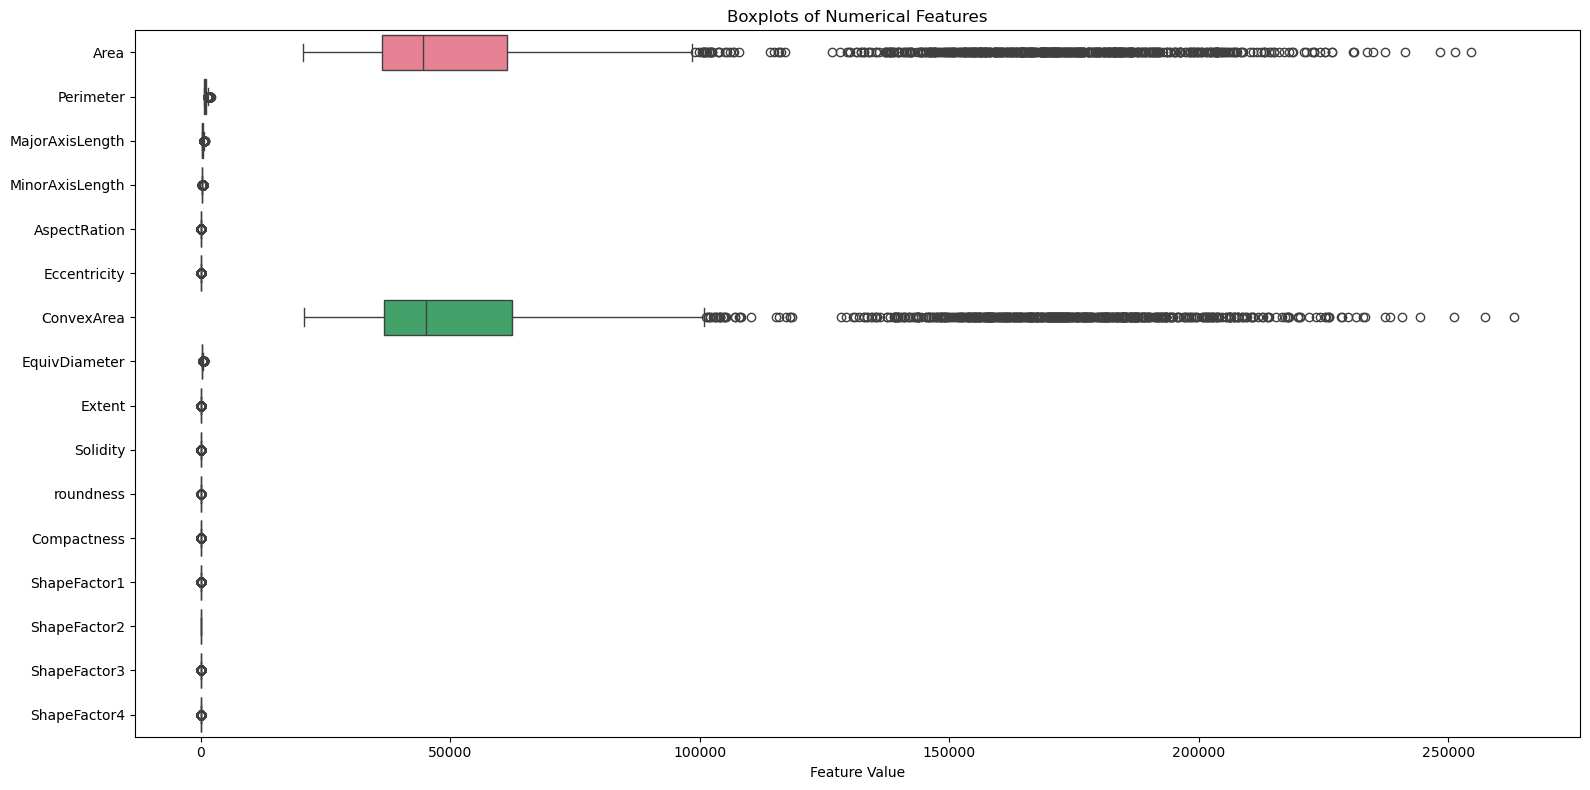

In [20]:
# Create boxplots for numerical features
plt.figure(figsize=(16, 8))

sns.boxplot(
    data=df_clean.drop(columns="Class"),
    orient="h"
)

plt.title("Boxplots of Numerical Features")
plt.xlabel("Feature Value")

plt.tight_layout()
plt.show()

## 8. Feature and Target Separation

The `Class` column is the target variable that represents the dry bean variety to be predicted. The remaining 16 numerical columns are used as predictor variables.

The predictor matrix is represented by `X`, while the target variable is represented by `y`.

In [21]:
# Separate predictor variables and target variable

X = df_clean.drop(columns="Class")
y = df_clean["Class"]

print(f"Number of predictor features: {X.shape[1]}")
print(f"Number of observations: {X.shape[0]}")
print(f"Target variable: {y.name}")

print("\nFeature columns:")
print(X.columns.tolist())

Number of predictor features: 16
Number of observations: 13543
Target variable: Class

Feature columns:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']


## 9. Train-Test Split

The cleaned dataset is divided into training and testing subsets using an 80:20 split.

Stratified sampling is used so that the relative distribution of the seven dry bean classes is maintained in both the training and testing datasets.

The test dataset is kept separate from model training and is used only for final model evaluation.

In [22]:
# Split the dataset into training and testing subsets
# Stratification preserves the class distribution in both subsets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training feature set shape: {X_train.shape}")
print(f"Testing feature set shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")

Training feature set shape: (10834, 16)
Testing feature set shape: (2709, 16)
Training target shape: (10834,)
Testing target shape: (2709,)


## 10. Verification of Stratified Sampling

The class distribution of the training and testing subsets is compared with the distribution of the complete cleaned dataset.

This verifies that stratified sampling has maintained a similar representation of each dry bean variety across the two subsets.

In [23]:
# Compare class distributions across the full, training, and testing datasets

distribution_check = pd.DataFrame({
    "Full Dataset (%)": y.value_counts(normalize=True) * 100,
    "Training Set (%)": y_train.value_counts(normalize=True) * 100,
    "Testing Set (%)": y_test.value_counts(normalize=True) * 100
}).round(2)

distribution_check = distribution_check.reset_index()
distribution_check = distribution_check.rename(columns={"index": "Class"})

display(distribution_check.style.hide(axis="index"))

Class,Full Dataset (%),Training Set (%),Testing Set (%)
DERMASON,26.180000,26.190000,26.170000
SIRA,19.460000,19.470000,19.450000
SEKER,14.970000,14.960000,14.990000
HOROZ,13.730000,13.730000,13.730000
CALI,12.040000,12.040000,12.030000
BARBUNYA,9.760000,9.760000,9.780000
BOMBAY,3.850000,3.860000,3.840000


## 11. Training and Testing Data Separation

The training and testing datasets must remain independent. The test set will not be used during model fitting or preprocessing parameter estimation.

This separation ensures that the evaluation metrics provide an unbiased estimate of model performance on unseen data.

In [24]:
# Verify that there is no exact overlap between training and testing observations

train_records = set(map(tuple, X_train.to_numpy()))
test_records = set(map(tuple, X_test.to_numpy()))

overlap = len(train_records.intersection(test_records))

print(f"Exact overlapping feature records between training and testing sets: {overlap}")

Exact overlapping feature records between training and testing sets: 0


## 12. Preprocessing Strategy

The predictor variables have substantially different numerical scales. Therefore, model-specific preprocessing is used.

Standardization is applied to Logistic Regression and K-Nearest Neighbors because these algorithms can be affected by differences in feature scale.

Decision Tree and Random Forest are tree-based algorithms and do not require feature scaling. Gaussian Naive Bayes is also trained using the original feature values.

Scalers are incorporated into machine learning pipelines so that preprocessing parameters are learned only from the training data, thereby preventing data leakage.

In [25]:
# Define model-specific preprocessing pipelines

logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=5
    ))
])

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

naive_bayes_model = GaussianNB()

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

print("Model preprocessing configurations created successfully.")

Model preprocessing configurations created successfully.


## 13. Model Training

Five supervised classification models are trained using the training dataset:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbor Classifier
4. Gaussian Naive Bayes
5. Random Forest Classifier

The test dataset is not used during model fitting and is reserved for final evaluation.

### 13.1 Logistic Regression

Logistic Regression is used as a baseline linear classification model. Since the predictor variables have substantially different numerical scales, StandardScaler is incorporated into the Logistic Regression pipeline.

The model is trained using the training dataset, while the test dataset is reserved for evaluation.

In [26]:
# Train Logistic Regression model
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


#### Generate Predictions

The trained Logistic Regression model is used to generate class predictions and class probabilities for the unseen test dataset.

Class probabilities are required for calculating the multiclass ROC-AUC score.

In [27]:
# Generate predictions on the test set
y_pred_lr = logistic_pipeline.predict(X_test)

# Generate class probabilities for multiclass AUC
y_proba_lr = logistic_pipeline.predict_proba(X_test)

print("Predictions generated successfully.")
print(f"Number of predictions: {len(y_pred_lr)}")
print(f"Probability matrix shape: {y_proba_lr.shape}")

Predictions generated successfully.
Number of predictions: 2709
Probability matrix shape: (2709, 7)


#### Logistic Regression Evaluation Metrics

The Logistic Regression model is evaluated using the six metrics specified in the assignment.

Because this is a seven-class classification problem, ROC-AUC is calculated using the One-vs-Rest (OvR) strategy with a weighted average.

Weighted averaging is also used for Precision, Recall, and F1 Score so that the contribution of each class reflects its representation in the test dataset.

In [28]:
# Calculate Logistic Regression evaluation metrics

lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_auc = roc_auc_score(
    y_test,
    y_proba_lr,
    multi_class="ovr",
    average="weighted"
)

lr_precision = precision_score(
    y_test,
    y_pred_lr,
    average="weighted",
    zero_division=0
)

lr_recall = recall_score(
    y_test,
    y_pred_lr,
    average="weighted",
    zero_division=0
)

lr_f1 = f1_score(
    y_test,
    y_pred_lr,
    average="weighted",
    zero_division=0
)

lr_mcc = matthews_corrcoef(
    y_test,
    y_pred_lr
)

print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy : {lr_accuracy:.4f}")
print(f"AUC      : {lr_auc:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1 Score : {lr_f1:.4f}")
print(f"MCC      : {lr_mcc:.4f}")

Logistic Regression Performance
--------------------------------
Accuracy : 0.9192
AUC      : 0.9934
Precision: 0.9197
Recall   : 0.9192
F1 Score : 0.9193
MCC      : 0.9023


#### Logistic Regression Classification Report

The classification report provides class-wise Precision, Recall, F1 Score, and support for each dry bean variety.

In [29]:
# Classification report for Logistic Regression
print("Logistic Regression Classification Report")
print("--------------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_lr,
        zero_division=0
    )
)

Logistic Regression Classification Report
--------------------------------------------
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



#### Logistic Regression Confusion Matrix

A confusion matrix is used to visualize the correct and incorrect predictions made by the Logistic Regression model for each dry bean class.

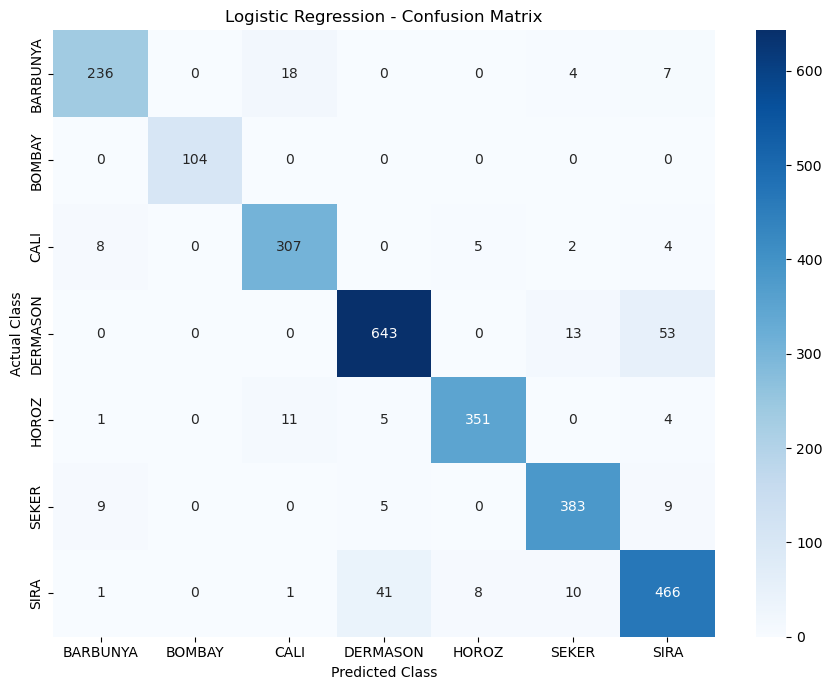

In [30]:
# Generate confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=logistic_pipeline.classes_,
    yticklabels=logistic_pipeline.classes_
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [31]:
# Store Logistic Regression results
results = []

results.append({
    "ML Model": "Logistic Regression",
    "Accuracy": lr_accuracy,
    "AUC": lr_auc,
    "Precision": lr_precision,
    "Recall": lr_recall,
    "F1 Score": lr_f1,
    "MCC": lr_mcc
})

results_df = pd.DataFrame(results)

display(results_df.round(4))

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023


## 14. Decision Tree Classifier

A Decision Tree Classifier is implemented as a nonlinear, tree-based classification model.

Unlike Logistic Regression and K-Nearest Neighbors, Decision Trees do not require feature standardization because their splitting decisions are based on feature thresholds rather than distances or coefficient magnitudes.

The model is trained using the training dataset and evaluated on the unseen test dataset.

In [32]:
# Train Decision Tree Classifier
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


### 14.1 Decision Tree Predictions

The trained Decision Tree is used to generate predicted classes and class probabilities for the test dataset.

In [33]:
# Generate Decision Tree predictions
y_pred_dt = decision_tree_model.predict(X_test)

# Generate class probabilities for multiclass AUC
y_proba_dt = decision_tree_model.predict_proba(X_test)

print("Predictions generated successfully.")
print(f"Number of predictions: {len(y_pred_dt)}")
print(f"Probability matrix shape: {y_proba_dt.shape}")

Predictions generated successfully.
Number of predictions: 2709
Probability matrix shape: (2709, 7)


### 14.2 Decision Tree Evaluation Metrics

The Decision Tree is evaluated using Accuracy, multiclass ROC-AUC, weighted Precision, weighted Recall, weighted F1 Score, and Matthews Correlation Coefficient.

The same evaluation methodology used for Logistic Regression is retained to ensure a fair comparison between models.

In [34]:
# Calculate Decision Tree evaluation metrics

dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_auc = roc_auc_score(
    y_test,
    y_proba_dt,
    multi_class="ovr",
    average="weighted"
)

dt_precision = precision_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

dt_recall = recall_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

dt_f1 = f1_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

dt_mcc = matthews_corrcoef(
    y_test,
    y_pred_dt
)

print("Decision Tree Performance")
print("-------------------------")
print(f"Accuracy : {dt_accuracy:.4f}")
print(f"AUC      : {dt_auc:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1 Score : {dt_f1:.4f}")
print(f"MCC      : {dt_mcc:.4f}")

Decision Tree Performance
-------------------------
Accuracy : 0.8966
AUC      : 0.9363
Precision: 0.8965
Recall   : 0.8966
F1 Score : 0.8964
MCC      : 0.8750


### 14.3 Decision Tree Classification Report

The classification report provides class-wise Precision, Recall, F1 Score, and support for the Decision Tree predictions.

In [35]:
# Classification report for Decision Tree

print("Decision Tree Classification Report")
print("------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_dt,
        zero_division=0
    )
)

Decision Tree Classification Report
------------------------------------
              precision    recall  f1-score   support

    BARBUNYA       0.88      0.90      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.91      0.91       326
    DERMASON       0.89      0.91      0.90       709
       HOROZ       0.95      0.92      0.94       372
       SEKER       0.91      0.94      0.92       406
        SIRA       0.84      0.81      0.82       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.90      2709



### 14.4 Decision Tree Confusion Matrix

The confusion matrix shows the distribution of correct and incorrect predictions made by the Decision Tree across the seven dry bean classes.

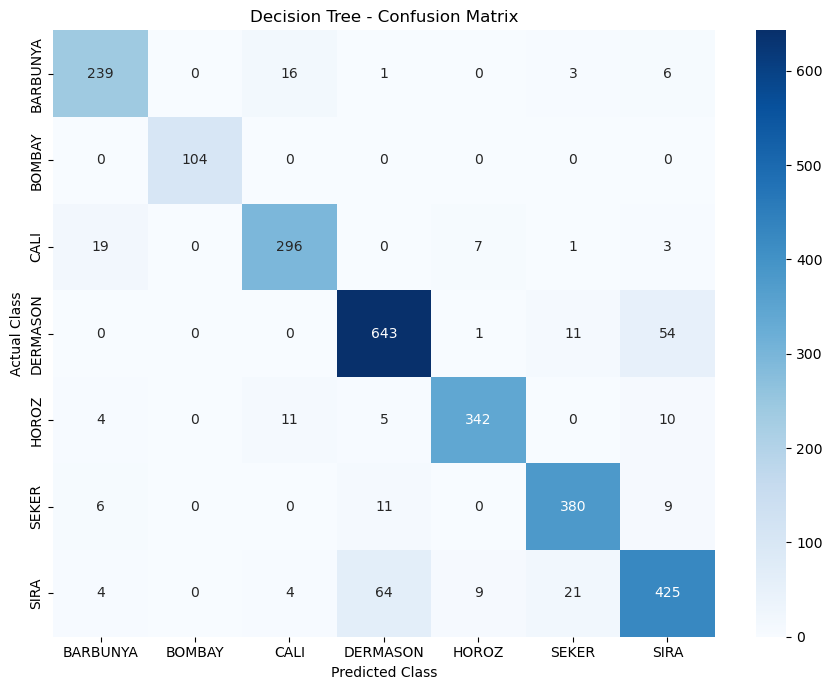

In [36]:
# Generate Decision Tree confusion matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=decision_tree_model.classes_,
    yticklabels=decision_tree_model.classes_
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [37]:
# Store model evaluation results

results = [
    {
        "ML Model": "Logistic Regression",
        "Accuracy": lr_accuracy,
        "AUC": lr_auc,
        "Precision": lr_precision,
        "Recall": lr_recall,
        "F1 Score": lr_f1,
        "MCC": lr_mcc
    },
    {
        "ML Model": "Decision Tree",
        "Accuracy": dt_accuracy,
        "AUC": dt_auc,
        "Precision": dt_precision,
        "Recall": dt_recall,
        "F1 Score": dt_f1,
        "MCC": dt_mcc
    }
]

results_df = pd.DataFrame(results)

display(results_df.round(4))

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750


## 15. K-Nearest Neighbors Classifier

K-Nearest Neighbors (KNN) is a distance-based classification algorithm that assigns a class to an observation based on the classes of its nearest neighboring observations.

Because KNN relies on distance calculations, differences in feature scale can strongly affect the results. Therefore, StandardScaler is incorporated into the KNN pipeline.

The model is trained using the training dataset and evaluated using the unseen test dataset.

In [38]:
# Train K-Nearest Neighbors model
knn_pipeline.fit(X_train, y_train)

print("K-Nearest Neighbors model trained successfully.")

K-Nearest Neighbors model trained successfully.


### 15.1 KNN Predictions

The trained KNN model is used to generate class predictions and class probabilities for the unseen test dataset.

The predicted probabilities are used to calculate the multiclass ROC-AUC score.

In [39]:
# Generate KNN predictions
y_pred_knn = knn_pipeline.predict(X_test)

# Generate class probabilities for multiclass AUC
y_proba_knn = knn_pipeline.predict_proba(X_test)

print("Predictions generated successfully.")
print(f"Number of predictions: {len(y_pred_knn)}")
print(f"Probability matrix shape: {y_proba_knn.shape}")

Predictions generated successfully.
Number of predictions: 2709
Probability matrix shape: (2709, 7)


### 15.2 KNN Evaluation Metrics

The KNN model is evaluated using the same six metrics used for the previous models: Accuracy, multiclass ROC-AUC, weighted Precision, weighted Recall, weighted F1 Score, and Matthews Correlation Coefficient.

The same test dataset and evaluation methodology are used to ensure a fair comparison between all classification models.

In [40]:
# Calculate KNN evaluation metrics

knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_auc = roc_auc_score(
    y_test,
    y_proba_knn,
    multi_class="ovr",
    average="weighted"
)

knn_precision = precision_score(
    y_test,
    y_pred_knn,
    average="weighted",
    zero_division=0
)

knn_recall = recall_score(
    y_test,
    y_pred_knn,
    average="weighted",
    zero_division=0
)

knn_f1 = f1_score(
    y_test,
    y_pred_knn,
    average="weighted",
    zero_division=0
)

knn_mcc = matthews_corrcoef(
    y_test,
    y_pred_knn
)

print("K-Nearest Neighbors Performance")
print("--------------------------------")
print(f"Accuracy : {knn_accuracy:.4f}")
print(f"AUC      : {knn_auc:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall   : {knn_recall:.4f}")
print(f"F1 Score : {knn_f1:.4f}")
print(f"MCC      : {knn_mcc:.4f}")

K-Nearest Neighbors Performance
--------------------------------
Accuracy : 0.9155
AUC      : 0.9811
Precision: 0.9163
Recall   : 0.9155
F1 Score : 0.9157
MCC      : 0.8978


### 15.3 KNN Classification Report

The classification report provides class-wise Precision, Recall, F1 Score, and support for the KNN predictions.

In [41]:
# Classification report for KNN

print("K-Nearest Neighbors Classification Report")
print("------------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_knn,
        zero_division=0
    )
)

K-Nearest Neighbors Classification Report
------------------------------------------
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.88      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.95      0.92       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.93      0.95       372
       SEKER       0.95      0.94      0.94       406
        SIRA       0.85      0.87      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



### 15.4 KNN Confusion Matrix

The confusion matrix is used to visualize the correct and incorrect KNN predictions across the seven dry bean classes.

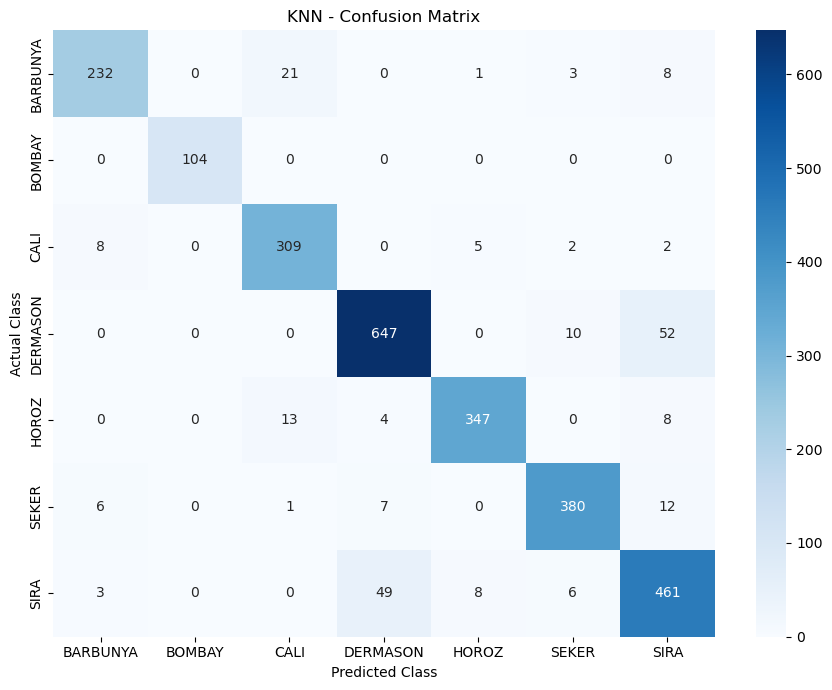

In [42]:
# Generate KNN confusion matrix

cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=knn_pipeline.classes_,
    yticklabels=knn_pipeline.classes_
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [43]:
# Update model evaluation results

results = [
    {
        "ML Model": "Logistic Regression",
        "Accuracy": lr_accuracy,
        "AUC": lr_auc,
        "Precision": lr_precision,
        "Recall": lr_recall,
        "F1 Score": lr_f1,
        "MCC": lr_mcc
    },
    {
        "ML Model": "Decision Tree",
        "Accuracy": dt_accuracy,
        "AUC": dt_auc,
        "Precision": dt_precision,
        "Recall": dt_recall,
        "F1 Score": dt_f1,
        "MCC": dt_mcc
    },
    {
        "ML Model": "KNN",
        "Accuracy": knn_accuracy,
        "AUC": knn_auc,
        "Precision": knn_precision,
        "Recall": knn_recall,
        "F1 Score": knn_f1,
        "MCC": knn_mcc
    }
]

results_df = pd.DataFrame(results)

display(results_df.round(4))

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
2,KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978


## 16. Gaussian Naive Bayes

Gaussian Naive Bayes is implemented as a probabilistic classification model. It assumes that the numerical predictor variables follow Gaussian distributions within each class and that the predictors are conditionally independent given the class.

The model is trained using the original numerical feature values without feature scaling because Gaussian Naive Bayes does not rely on distance calculations.

In [44]:
# Train Gaussian Naive Bayes model
naive_bayes_model.fit(X_train, y_train)

print("Gaussian Naive Bayes model trained successfully.")

Gaussian Naive Bayes model trained successfully.


### 16.1 Gaussian Naive Bayes Predictions

The trained Gaussian Naive Bayes model is used to generate class predictions and class probabilities for the unseen test dataset.

In [45]:
# Generate Gaussian Naive Bayes predictions
y_pred_nb = naive_bayes_model.predict(X_test)

# Generate class probabilities for multiclass AUC
y_proba_nb = naive_bayes_model.predict_proba(X_test)

print("Predictions generated successfully.")
print(f"Number of predictions: {len(y_pred_nb)}")
print(f"Probability matrix shape: {y_proba_nb.shape}")

Predictions generated successfully.
Number of predictions: 2709
Probability matrix shape: (2709, 7)


### 16.2 Gaussian Naive Bayes Evaluation Metrics

The Gaussian Naive Bayes model is evaluated using Accuracy, multiclass ROC-AUC, weighted Precision, weighted Recall, weighted F1 Score, and Matthews Correlation Coefficient.

The same test dataset and evaluation methodology used for the other models are retained for a fair comparison.

In [46]:
# Calculate Gaussian Naive Bayes evaluation metrics

nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_auc = roc_auc_score(
    y_test,
    y_proba_nb,
    multi_class="ovr",
    average="weighted"
)

nb_precision = precision_score(
    y_test,
    y_pred_nb,
    average="weighted",
    zero_division=0
)

nb_recall = recall_score(
    y_test,
    y_pred_nb,
    average="weighted",
    zero_division=0
)

nb_f1 = f1_score(
    y_test,
    y_pred_nb,
    average="weighted",
    zero_division=0
)

nb_mcc = matthews_corrcoef(
    y_test,
    y_pred_nb
)

print("Gaussian Naive Bayes Performance")
print("---------------------------------")
print(f"Accuracy : {nb_accuracy:.4f}")
print(f"AUC      : {nb_auc:.4f}")
print(f"Precision: {nb_precision:.4f}")
print(f"Recall   : {nb_recall:.4f}")
print(f"F1 Score : {nb_f1:.4f}")
print(f"MCC      : {nb_mcc:.4f}")

Gaussian Naive Bayes Performance
---------------------------------
Accuracy : 0.7630
AUC      : 0.9644
Precision: 0.7647
Recall   : 0.7630
F1 Score : 0.7607
MCC      : 0.7143


### 16.3 Gaussian Naive Bayes Classification Report

The classification report provides class-wise Precision, Recall, F1 Score, and support for the Gaussian Naive Bayes predictions.

In [47]:
# Classification report for Gaussian Naive Bayes

print("Gaussian Naive Bayes Classification Report")
print("--------------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_nb,
        zero_division=0
    )
)

Gaussian Naive Bayes Classification Report
--------------------------------------------
              precision    recall  f1-score   support

    BARBUNYA       0.68      0.46      0.55       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.69      0.83      0.75       326
    DERMASON       0.87      0.82      0.85       709
       HOROZ       0.78      0.79      0.79       372
       SEKER       0.67      0.70      0.68       406
        SIRA       0.73      0.77      0.75       527

    accuracy                           0.76      2709
   macro avg       0.77      0.77      0.77      2709
weighted avg       0.76      0.76      0.76      2709



### 16.4 Gaussian Naive Bayes Confusion Matrix

The confusion matrix is used to visualize the correct and incorrect predictions made by Gaussian Naive Bayes across the seven dry bean classes.

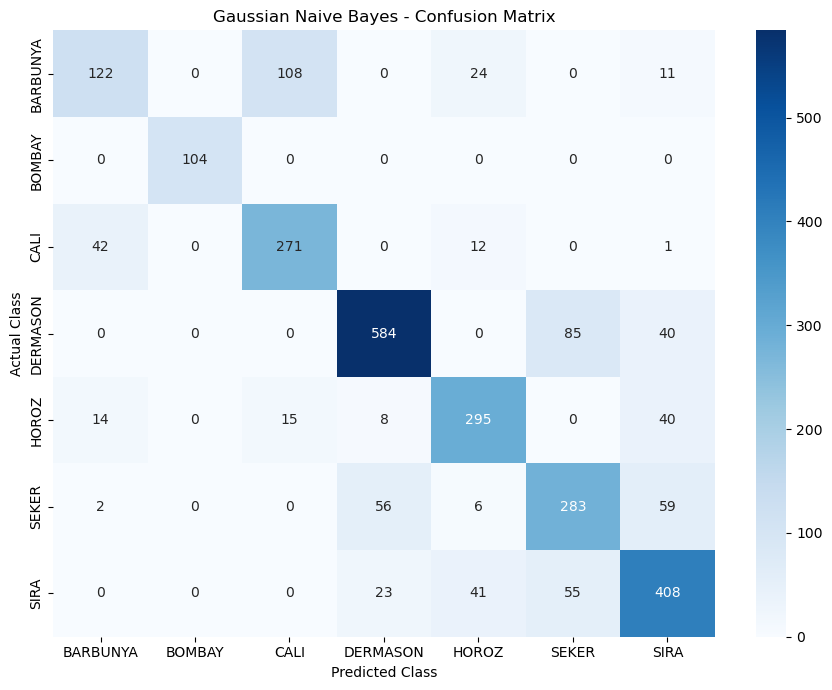

In [48]:
# Generate Gaussian Naive Bayes confusion matrix

cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=naive_bayes_model.classes_,
    yticklabels=naive_bayes_model.classes_
)

plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [49]:
# Update model evaluation results

results = [
    {
        "ML Model": "Logistic Regression",
        "Accuracy": lr_accuracy,
        "AUC": lr_auc,
        "Precision": lr_precision,
        "Recall": lr_recall,
        "F1 Score": lr_f1,
        "MCC": lr_mcc
    },
    {
        "ML Model": "Decision Tree",
        "Accuracy": dt_accuracy,
        "AUC": dt_auc,
        "Precision": dt_precision,
        "Recall": dt_recall,
        "F1 Score": dt_f1,
        "MCC": dt_mcc
    },
    {
        "ML Model": "KNN",
        "Accuracy": knn_accuracy,
        "AUC": knn_auc,
        "Precision": knn_precision,
        "Recall": knn_recall,
        "F1 Score": knn_f1,
        "MCC": knn_mcc
    },
    {
        "ML Model": "Gaussian Naive Bayes",
        "Accuracy": nb_accuracy,
        "AUC": nb_auc,
        "Precision": nb_precision,
        "Recall": nb_recall,
        "F1 Score": nb_f1,
        "MCC": nb_mcc
    }
]

results_df = pd.DataFrame(results)

display(results_df.round(4))

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
2,KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
3,Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143


## 17. Random Forest Classifier

Random Forest is an ensemble learning method that combines multiple decision trees to produce a more robust classification model.

Each tree is trained using a randomized subset of the training data and features, and the final prediction is obtained by aggregating the predictions of the individual trees.

Random Forest is evaluated on the same unseen test dataset used for all previous models to ensure a fair comparison.

In [50]:
# Train Random Forest model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


### 17.1 Random Forest Predictions

The trained Random Forest model is used to generate predicted classes and class probabilities for the unseen test dataset.

The predicted class probabilities are used to calculate the multiclass ROC-AUC score.

In [51]:
# Generate Random Forest predictions
y_pred_rf = random_forest_model.predict(X_test)

# Generate class probabilities for multiclass AUC
y_proba_rf = random_forest_model.predict_proba(X_test)

print("Predictions generated successfully.")
print(f"Number of predictions: {len(y_pred_rf)}")
print(f"Probability matrix shape: {y_proba_rf.shape}")

Predictions generated successfully.
Number of predictions: 2709
Probability matrix shape: (2709, 7)


### 17.2 Random Forest Evaluation Metrics

The Random Forest model is evaluated using the same six metrics used for all previous models: Accuracy, multiclass ROC-AUC, weighted Precision, weighted Recall, weighted F1 Score, and Matthews Correlation Coefficient.

Using the same test dataset and evaluation procedure allows direct comparison with the other classification models.

In [52]:
# Calculate Random Forest evaluation metrics

rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_auc = roc_auc_score(
    y_test,
    y_proba_rf,
    multi_class="ovr",
    average="weighted"
)

rf_precision = precision_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

rf_mcc = matthews_corrcoef(
    y_test,
    y_pred_rf
)

print("Random Forest Performance")
print("-------------------------")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"AUC      : {rf_auc:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"MCC      : {rf_mcc:.4f}")

Random Forest Performance
-------------------------
Accuracy : 0.9203
AUC      : 0.9923
Precision: 0.9203
Recall   : 0.9203
F1 Score : 0.9202
MCC      : 0.9035


### 17.3 Random Forest Classification Report

The classification report provides class-wise Precision, Recall, F1 Score, and support for the Random Forest predictions.

In [53]:
# Classification report for Random Forest

print("Random Forest Classification Report")
print("------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_rf,
        zero_division=0
    )
)

Random Forest Classification Report
------------------------------------
              precision    recall  f1-score   support

    BARBUNYA       0.92      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.92      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.94      0.96      0.95       406
        SIRA       0.87      0.86      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



### 17.4 Random Forest Confusion Matrix

The confusion matrix shows the correct and incorrect Random Forest predictions across the seven Dry Bean classes.

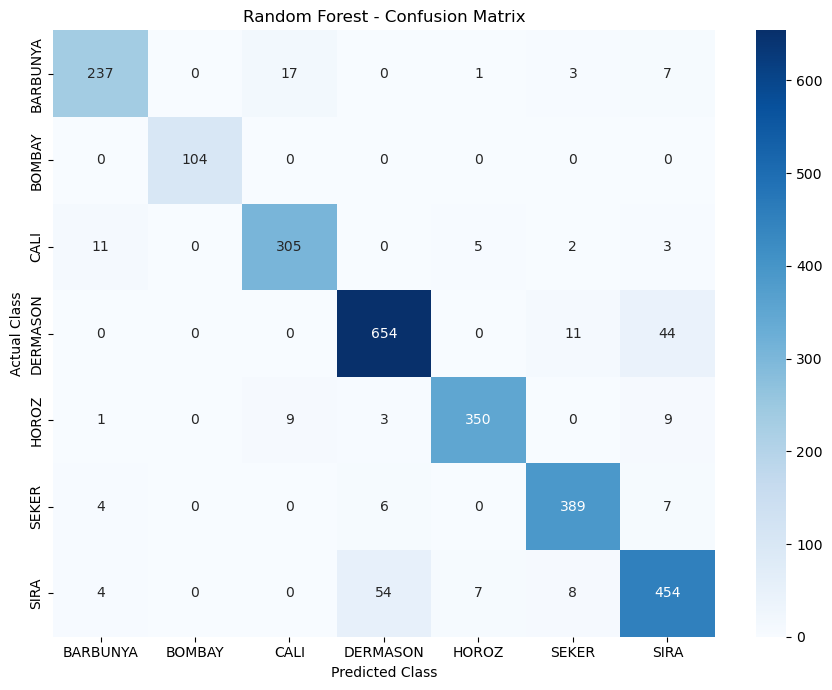

In [54]:
# Generate Random Forest confusion matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=random_forest_model.classes_,
    yticklabels=random_forest_model.classes_
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [55]:
# Final model evaluation comparison

results = [
    {
        "ML Model": "Logistic Regression",
        "Accuracy": lr_accuracy,
        "AUC": lr_auc,
        "Precision": lr_precision,
        "Recall": lr_recall,
        "F1 Score": lr_f1,
        "MCC": lr_mcc
    },
    {
        "ML Model": "Decision Tree",
        "Accuracy": dt_accuracy,
        "AUC": dt_auc,
        "Precision": dt_precision,
        "Recall": dt_recall,
        "F1 Score": dt_f1,
        "MCC": dt_mcc
    },
    {
        "ML Model": "KNN",
        "Accuracy": knn_accuracy,
        "AUC": knn_auc,
        "Precision": knn_precision,
        "Recall": knn_recall,
        "F1 Score": knn_f1,
        "MCC": knn_mcc
    },
    {
        "ML Model": "Gaussian Naive Bayes",
        "Accuracy": nb_accuracy,
        "AUC": nb_auc,
        "Precision": nb_precision,
        "Recall": nb_recall,
        "F1 Score": nb_f1,
        "MCC": nb_mcc
    },
    {
        "ML Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "AUC": rf_auc,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1 Score": rf_f1,
        "MCC": rf_mcc
    }
]

results_df = pd.DataFrame(results)

display(results_df.round(4))

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
2,KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
3,Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143
4,Random Forest,0.9203,0.9923,0.9203,0.9203,0.9202,0.9035


# 18. Final Model Comparison and Analysis

All five classification models were evaluated using the same training and testing datasets and the same six evaluation metrics.

The results are summarized below.

In [56]:
# Display Results


results_df

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
2,KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
3,Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143
4,Random Forest,0.9203,0.9923,0.9203,0.9203,0.9202,0.9035


## 18.1 Model Performance Observations

### 18.2 Visual Comparison of Model Performance

The following visualization compares the performance of all implemented classification models across the six evaluation metrics.

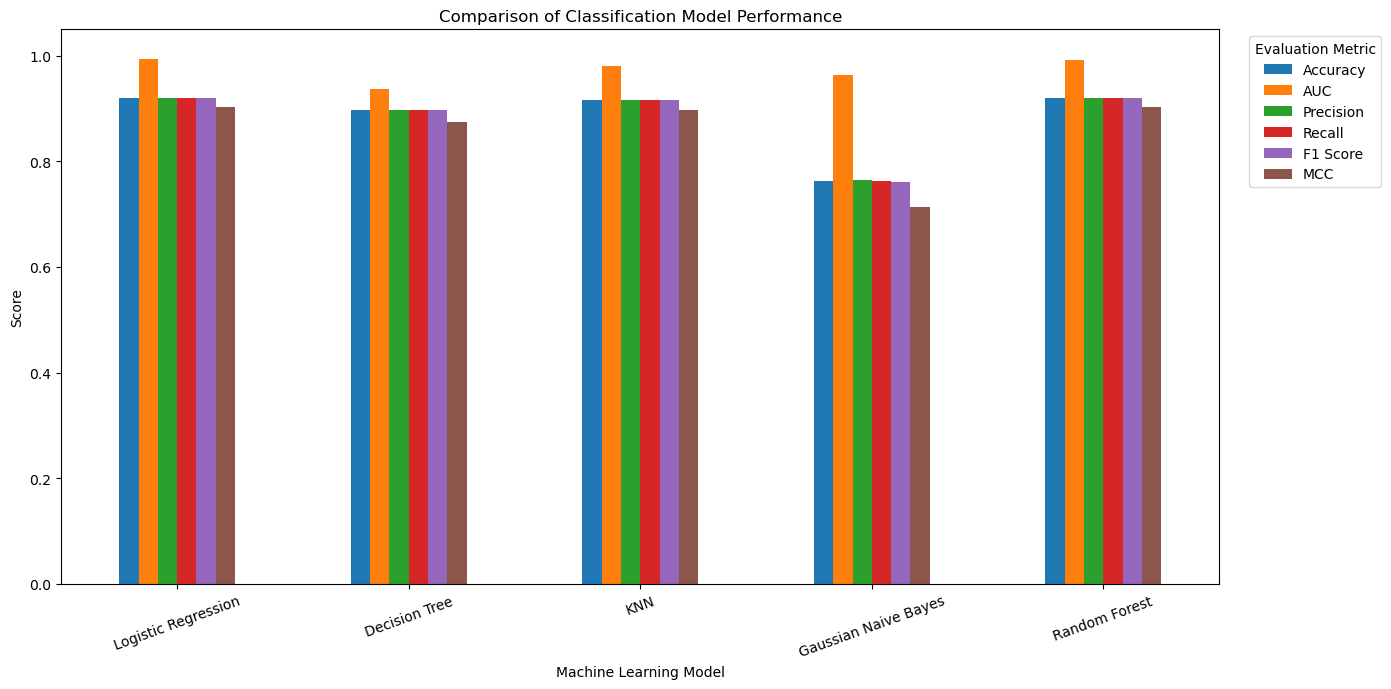

In [57]:
# Prepare data for visualization
comparison_plot = results_df.set_index("ML Model")

# Plot model performance comparison
comparison_plot.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Comparison of Classification Model Performance")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(title="Evaluation Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [58]:
# Rank models based on Accuracy
model_ranking = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

model_ranking.insert(
    0,
    "Rank",
    range(1, len(model_ranking) + 1)
)

display(model_ranking.round(4))

,Rank,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,1,Random Forest,0.9203,0.9923,0.9203,0.9203,0.9202,0.9035
1,2,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
2,3,KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
3,4,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
4,5,Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143


### 18.3 Random Forest Feature Importance

Since Random Forest achieved the best overall performance across five of the six evaluation metrics, its feature importance values are examined to identify which predictor variables contributed most strongly to the model's classification decisions.

Feature importance is used for interpretation and does not imply a causal relationship between a feature and the target class.

In [59]:
# Extract Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

,Feature,Importance
0,ShapeFactor3,0.0970
1,ShapeFactor1,0.0964
2,Compactness,0.0953
3,Perimeter,0.0910
4,MinorAxisLength,0.0779
5,ConvexArea,0.0772
6,MajorAxisLength,0.0726
7,Eccentricity,0.0626
8,roundness,0.0611
9,AspectRation,0.0589


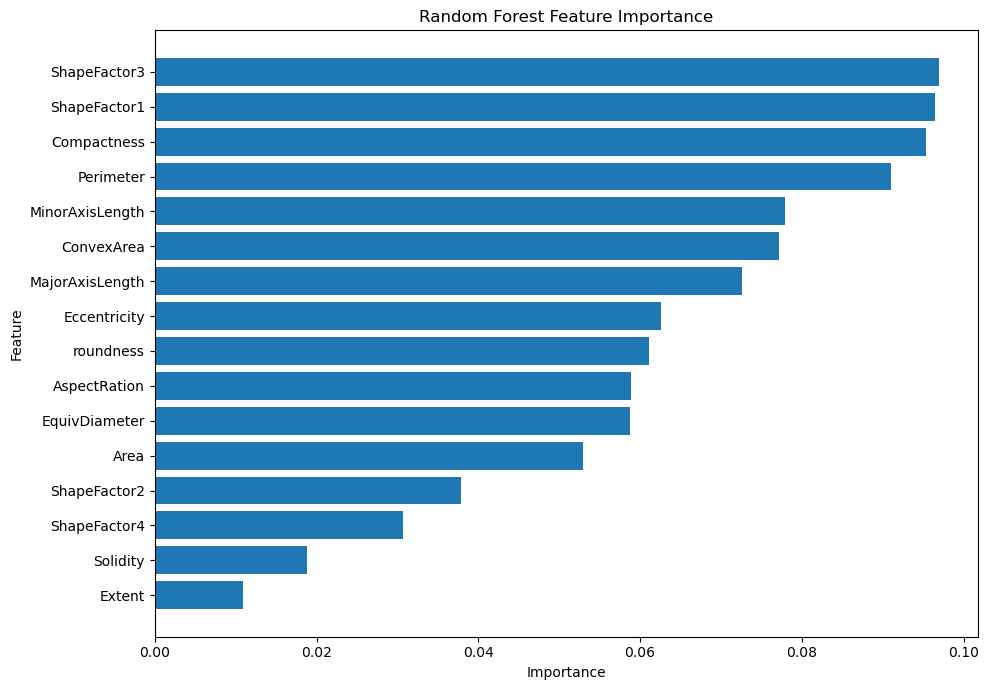

In [60]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

#  Final Model Comparison and Analysis

All five classification models were evaluated on the same unseen test dataset containing 2,709 observations. The models were compared using Accuracy, multiclass ROC-AUC, weighted Precision, weighted Recall, weighted F1 Score, and Matthews Correlation Coefficient (MCC).

In [61]:
# Display final model comparison

display(results_df.round(4))

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
2,KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
3,Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143
4,Random Forest,0.9203,0.9923,0.9203,0.9203,0.9202,0.9035


##  Model Ranking

The models are ranked based on their test-set Accuracy. The ranking provides a concise view of the relative predictive performance of the implemented classifiers.

In [62]:
# Rank models based on Accuracy

model_ranking = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

model_ranking.insert(
    0,
    "Rank",
    range(1, len(model_ranking) + 1)
)

display(model_ranking.round(4))

,Rank,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,1,Random Forest,0.9203,0.9923,0.9203,0.9203,0.9202,0.9035
1,2,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
2,3,KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
3,4,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
4,5,Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143


## 18.2 Comparison of Model Performance

The following visualization compares the six evaluation metrics across all five classification models.

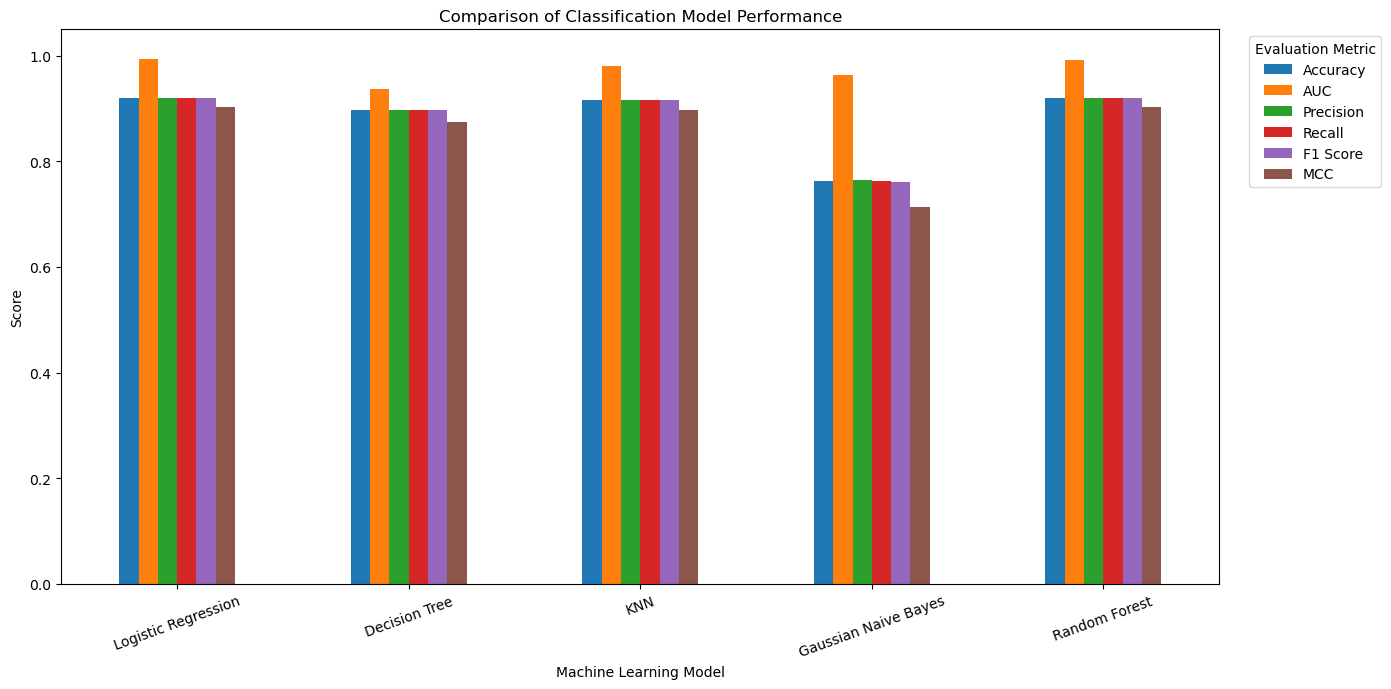

In [63]:
# Visual comparison of model performance

comparison_plot = results_df.set_index("ML Model")

comparison_plot.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Comparison of Classification Model Performance")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(
    title="Evaluation Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

#  **Logistic Regression**

Logistic Regression achieved strong and consistent performance, with an accuracy of 91.92%, weighted F1 score of 91.93%, and MCC of 90.23%. It achieved the highest AUC of 99.34% among all evaluated models, indicating excellent class-separation capability. Its overall performance was slightly below Random Forest on most classification metrics.

#  **Decision Tree**

Decision Tree achieved an accuracy of 89.66% and MCC of 87.50%. Its performance was lower than Logistic Regression and KNN across the main classification metrics. The model showed noticeable confusion between the DERMASON and SIRA classes, contributing to its lower overall performance.

#  **KNN**

KNN achieved strong performance with an accuracy of 91.55%, weighted F1 score of 91.57%, and MCC of 89.78%. Its performance was close to Logistic Regression and Random Forest, demonstrating that distance-based classification is effective for this dataset when feature scaling is applied.

#  **Gaussian Naive Bayes**

Gaussian Naive Bayes produced the lowest overall classification performance, with an accuracy of 76.30%, weighted F1 score of 76.07%, and MCC of 71.43%. Although its AUC was relatively high at 96.44%, its classification accuracy was substantially lower than the other models. The model showed considerable confusion among several bean classes, particularly BARBUNYA, CALI, SEKER, and SIRA.

#  **Random Forest**

Random Forest achieved the best overall classification performance, with the highest accuracy (92.03%), precision (92.03%), recall (92.03%), F1 score (92.02%), and MCC (90.35%). It achieved the second-highest AUC of 99.23%, slightly below Logistic Regression's 99.34%. Its ensemble structure provided strong and consistent performance across the evaluation metrics.

#  **Overall Winner: Random Forest (Ensemble)**


Random Forest is selected as the overall best-performing model because it achieved the highest Accuracy, Precision, Recall, F1 Score, and MCC among the five evaluated models. Although Logistic Regression achieved a slightly higher AUC, Random Forest demonstrated the strongest overall classification performance across five of the six required evaluation metrics.

##  Random Forest Feature Importance

Since Random Forest achieved the best overall performance across five of the six evaluation metrics, its feature importance values were examined to identify the predictor variables that contributed most strongly to the model's classification decisions.

The three highest-ranked features were ShapeFactor3, ShapeFactor1, and Compactness. Extent had the lowest feature importance among the 16 predictors.

Feature importance represents the contribution of a feature to the trained model's predictive decisions and should not be interpreted as a causal relationship.

In [64]:
# Calculate Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

,Feature,Importance
0,ShapeFactor3,0.0970
1,ShapeFactor1,0.0964
2,Compactness,0.0953
3,Perimeter,0.0910
4,MinorAxisLength,0.0779
5,ConvexArea,0.0772
6,MajorAxisLength,0.0726
7,Eccentricity,0.0626
8,roundness,0.0611
9,AspectRation,0.0589


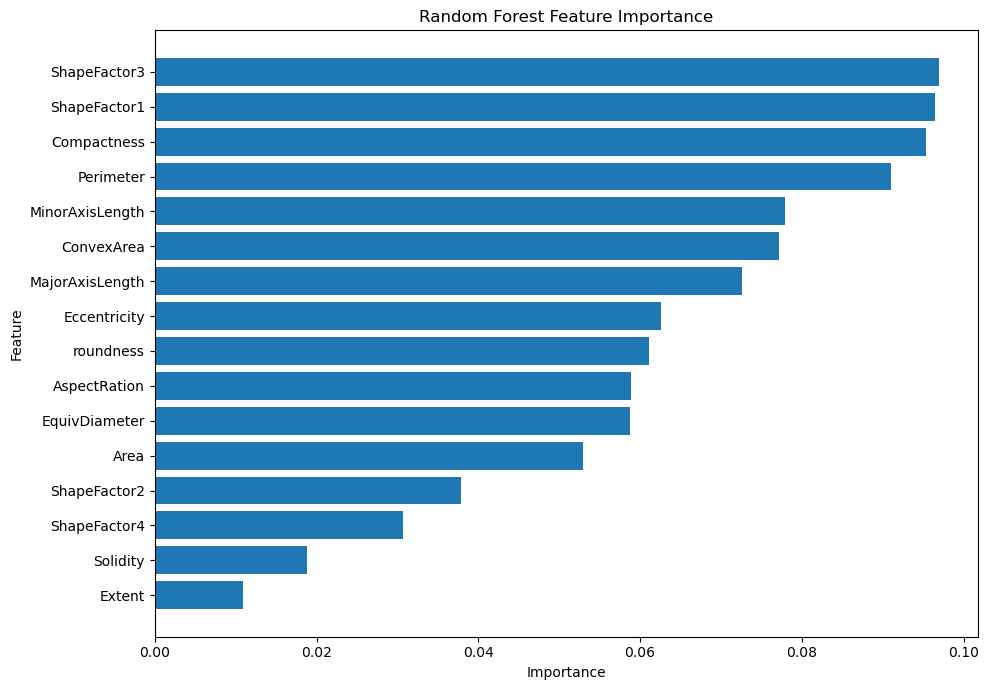

In [65]:
# Plot Random Forest feature importance

plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [67]:
# Create the model directory

import os
import joblib

# Create a folder for the trained models
os.makedirs("models", exist_ok=True)

# Save the trained models
joblib.dump(logistic_pipeline, "models/logistic_pipeline.pkl")
joblib.dump(decision_tree_model, "models/decision_tree_model.pkl")
joblib.dump(knn_pipeline, "models/knn_pipeline.pkl")
joblib.dump(naive_bayes_model, "models/naive_bayes_model.pkl")
joblib.dump(random_forest_model, "models/random_forest_model.pkl")

print("All five models saved successfully!")

All five models saved successfully!


In [71]:
# Verify that all models were saved

import os

model_files = os.listdir("models")

print("Saved model files:")
for file in sorted(model_files):
    print("-", file)

Saved model files:
- decision_tree_model.pkl
- knn_pipeline.pkl
- logistic_pipeline.pkl
- naive_bayes_model.pkl
- random_forest_model.pkl


In [69]:
# Verify that the saved models can actually be loaded

import joblib

# Load saved models
loaded_logistic = joblib.load("models/logistic_pipeline.pkl")
loaded_decision_tree = joblib.load("models/decision_tree_model.pkl")
loaded_knn = joblib.load("models/knn_pipeline.pkl")
loaded_naive_bayes = joblib.load("models/naive_bayes_model.pkl")
loaded_random_forest = joblib.load("models/random_forest_model.pkl")

print("All models loaded successfully!")

All models loaded successfully!


In [72]:
# Check the test data that was used during model evaluation

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nX_test columns:")
print(X_test.columns.tolist())

print("\nFirst 5 rows of X_test:")
display(X_test.head())

print("\ny_test:")
display(y_test.head())

X_test shape: (2709, 16)
y_test shape: (2709,)

X_test columns:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

First 5 rows of X_test:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
1223,40512,737.6360,248.2020,208.5252,1.1903,0.5424,40973,227.1156,0.7443,0.9887,0.9356,0.9150,0.0061,0.0026,0.8373,0.9966
11769,31890,660.6550,250.4173,162.5225,1.5408,0.7608,32240,201.5034,0.8020,0.9891,0.9182,0.8047,0.0079,0.0020,0.6475,0.9977
12059,33107,671.8690,244.7283,172.9381,1.4151,0.7076,33506,205.3123,0.7987,0.9881,0.9216,0.8389,0.0074,0.0023,0.7038,0.9960
7126,61684,984.8780,412.1156,191.4733,2.1523,0.8855,62303,280.2472,0.7847,0.9901,0.7991,0.6800,0.0067,0.0009,0.4624,0.9953
638,37189,700.2530,243.3434,194.9101,1.2485,0.5987,37534,217.6017,0.7848,0.9908,0.9530,0.8942,0.0065,0.0026,0.7996,0.9983



y_test:


1223        SEKER
11769    DERMASON
12059    DERMASON
7126        HOROZ
638         SEKER
Name: Class, dtype: object

In [74]:
# Create a copy so the original test data is not modified
test_data = X_test.copy()

# Add the actual target/class
test_data["Class"] = y_test.values



print("Test data shape:", test_data.shape)
print("\nColumns:")
print(test_data.columns.tolist())


Test data shape: (2709, 17)

Columns:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


In [75]:
# Verify the test CSV before saving

## Check missing values
print(
    "Total missing values:",
    test_data.isnull().sum().sum()
)

## Check number of rows
print("Number of test observations:", len(test_data))

## Check class distribution
print(test_data["Class"].value_counts())

Total missing values: 0
Number of test observations: 2709
Class
DERMASON    709
SIRA        527
SEKER       406
HOROZ       372
CALI        326
BARBUNYA    265
BOMBAY      104
Name: count, dtype: int64


In [76]:
# Save the exact test data used for evaluation


test_data.to_csv("test_data.csv", index=False)

print("test_data.csv created successfully!")


test_data.csv created successfully!


In [77]:
# Verify

import os

print(
    "File exists:",
    os.path.exists("test_data.csv")
)

print(
    "File size:",
    os.path.getsize("test_data.csv"),
    "bytes"
)

File exists: True
File size: 761674 bytes


In [79]:
# Read the CSV back to verify that it was saved correctly

test_check = pd.read_csv("test_data.csv")

print("Loaded test_data.csv successfully")
print("Shape:", test_check.shape)

print("\nColumns:")
print(test_check.columns.tolist())

print("\nMissing values:")
print(test_check.isnull().sum())

print("\nClass distribution:")
print(test_check["Class"].value_counts())

print("\nFirst 5 rows:")
display(test_check.head())

Loaded test_data.csv successfully
Shape: (2709, 17)

Columns:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Missing values:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Class distribution:
Class
DERMASON    709
SIRA        527
SEKER       406
HOROZ       372
CALI        326
BARBUNYA    265
BOMBAY      104
Name: count, dtype: int64

First 5 rows:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,40512,737.6360,248.2020,208.5252,1.1903,0.5424,40973,227.1156,0.7443,0.9887,0.9356,0.9150,0.0061,0.0026,0.8373,0.9966,SEKER
1,31890,660.6550,250.4173,162.5225,1.5408,0.7608,32240,201.5034,0.8020,0.9891,0.9182,0.8047,0.0079,0.0020,0.6475,0.9977,DERMASON
2,33107,671.8690,244.7283,172.9381,1.4151,0.7076,33506,205.3123,0.7987,0.9881,0.9216,0.8389,0.0074,0.0023,0.7038,0.9960,DERMASON
3,61684,984.8780,412.1156,191.4733,2.1523,0.8855,62303,280.2472,0.7847,0.9901,0.7991,0.6800,0.0067,0.0009,0.4624,0.9953,HOROZ
4,37189,700.2530,243.3434,194.9101,1.2485,0.5987,37534,217.6017,0.7848,0.9908,0.9530,0.8942,0.0065,0.0026,0.7996,0.9983,SEKER


In [80]:
# Predictions from original model
original_predictions = random_forest_model.predict(X_test)

# Predictions from saved-and-reloaded model
loaded_predictions = loaded_random_forest.predict(X_test)

# Compare predictions
same_predictions = (original_predictions == loaded_predictions).all()

print("Original accuracy:",
      accuracy_score(y_test, original_predictions))

print("Loaded model accuracy:",
      accuracy_score(y_test, loaded_predictions))

print("Predictions identical:", same_predictions)

Original accuracy: 0.920265780730897
Loaded model accuracy: 0.920265780730897
Predictions identical: True


In [82]:
# Check the final files

import os

print("Files created:")
print()

for root, dirs, files in os.walk("."):
    for file in files:
        if file.endswith(".pkl") or file == "test_data.csv":
            print(os.path.join(root, file))

Files created:

.\test_data.csv
.\models\decision_tree_model.pkl
.\models\knn_pipeline.pkl
.\models\logistic_pipeline.pkl
.\models\naive_bayes_model.pkl
.\models\random_forest_model.pkl
